# Compulsion-to-closure probe

**Goal:** detect and quantify a learned disposition in post-trained LLMs to terminate work and emit a final answer rather than invoke an available `verify` tool, even when verification would clearly help.

**Falsifiable headline metric — discrimination slope.**
Across MATH levels 1–5 (substrate gets monotonically harder, single-shot pass rate falls), how much does P(verify) rise with level?

- *Closure-bias hypothesis*: under neutral prompting, slope is small or zero (model under-discriminates). Under anti-bias prompting, slope is large (or pinned to 100%).
- *Null hypothesis*: slope under neutral matches slope under anti-bias.

Three conditions × five difficulty levels × multiple model generations.

**Architecture:** model solves in plain assistant text. Two custom MCP tools: `verify(answer) -> bool` (oracle hidden as self-check) and `submit(answer)` (terminator). All Claude Code skills/MCP/tools stripped via `setting_sources=[]`, `strict_mcp_config=True`, `disallowed_tools`.

## 0. Setup

In [1]:
from __future__ import annotations

import asyncio
import contextvars
import os
import random
import time
from collections import Counter, defaultdict
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import sympy as sp
from datasets import concatenate_datasets, load_dataset
from math_verify import parse, verify

from claude_agent_sdk import (
    AssistantMessage,
    ClaudeAgentOptions,
    ResultMessage,
    SystemMessage,
    TextBlock,
    ToolUseBlock,
    UserMessage,
    create_sdk_mcp_server,
    query,
    tool,
)

RESULTS_DIR = Path("./results")
RESULTS_DIR.mkdir(exist_ok=True)

# Bedrock model IDs — generation axis for the orthogonality probe.
# Cross-region inference profile prefix (us.) is required.
# Haiku 3 is excluded: it predates prompt caching, which the Claude Code CLI
# always sends, so every request is rejected with a 400 by Bedrock.
MODELS = {
    "haiku-3.5": "us.anthropic.claude-3-5-haiku-20241022-v1:0",
    "haiku-4.5": "us.anthropic.claude-haiku-4-5-20251001-v1:0",
}

SEED = 0
random.seed(SEED)

## 1. Build the problem pool

Sample N problems from each MATH level (1 → 5), all subjects pooled, deterministic seed. We keep only rows with `\boxed{...}` (the dataset's marker that the answer is a discrete value, not a proof). Verification uses `math_verify` directly — it handles fractions, radicals, $\pi$, etc.

In [2]:
SUBJECTS = [
    "algebra", "counting_and_probability", "geometry",
    "intermediate_algebra", "number_theory", "prealgebra", "precalculus",
]

# Use the test split. Train was 100% saturated by Haiku 4.5 on Level 5,
# almost certainly because MATH-train has been in pretraining since 2021.
# Test is also widely benchmarked, so contamination isn't zero, but it's the
# cheaper first defense before switching to a harder dataset.
_data = concatenate_datasets([
    load_dataset("EleutherAI/hendrycks_math", s)["test"] for s in SUBJECTS
])
print(f"loaded {len(_data)} test problems")

loaded 5000 test problems


In [3]:
rng = random.Random(SEED)
_pool_l1 = [ex for ex in _data if ex["level"] == "Level 1" and r"\boxed{" in ex["solution"]]
_pool_l5 = [ex for ex in _data if ex["level"] == "Level 5" and r"\boxed{" in ex["solution"]]

NUM_PROBLEMS = 50

EASY = rng.sample(_pool_l1, NUM_PROBLEMS)
HARD = rng.sample(_pool_l5, NUM_PROBLEMS)

print(f"easy candidates (Level 1, any subject): {len(_pool_l1)}, sampled {NUM_PROBLEMS}")
print(f"hard candidates (Level 5, any subject): {len(_pool_l5)}, sampled {NUM_PROBLEMS}")
EASY[0]

easy candidates (Level 1, any subject): 437, sampled 50
hard candidates (Level 5, any subject): 1324, sampled 50


{'problem': 'Compute $\\tan 135^\\circ$.',
 'level': 'Level 1',
 'type': 'Precalculus',
 'solution': 'Let $P$ be the point on the unit circle that is $135^\\circ$ counterclockwise from $(1,0)$, and let $D$ be the foot of the altitude from $P$ to the $x$-axis, as shown below.\n\n[asy]\n\npair A,C,P,O,D;\n\ndraw((0,-1.2)--(0,1.2),p=black+1.2bp,Arrows(0.15cm));\n\ndraw((-1.2,0)--(1.2,0),p=black+1.2bp,Arrows(0.15cm));\n\nA = (1,0);\n\nO= (0,0);\n\nlabel("$x$",(1.2,0),SE);\n\nlabel("$y$",(0,1.2),NE);\n\nP = rotate(135)*A;\n\nD = foot(P,A,-A);\n\ndraw(O--P--D);\n\ndraw(rightanglemark(O,D,P,2));\n\ndraw(Circle(O,1));\n\nlabel("$O$",O,SE);\n\nlabel("$P$",P,NW);\n\n//label("$A$",A,SE);\n\nlabel("$D$",D,S);\n\n[/asy]\n\nTriangle $POD$ is a 45-45-90 triangle, so $DO = DP = \\frac{\\sqrt{2}}{2}$.  Therefore, the coordinates of $P$ are $\\left(-\\frac{\\sqrt{2}}{2}, \\frac{\\sqrt{2}}{2}\\right)$, so \\[\\tan 135^\\circ = \\frac{\\sin 135^\\circ}{\\cos 135^\\circ} = \\frac{\\sqrt{2}/2}{-\\sqrt{2}/2}

## 2. Substrate sanity check

**Gating step.** Before measuring whether the model *chooses* to verify, confirm it *can* solve at the target rates. We run all 60 problems once through Haiku 4.5 with no tools — just plain assistant text asking for `\boxed{}`. The targets are easy ≥85%, hard ∈ [40%, 65%].

If outside targets, broaden / narrow the level filter in Section 1 before proceeding.

In [4]:
def gold_correct(solution_text: str, candidate_text: str) -> bool:
    """True iff candidate_text matches the gold answer in solution_text per math_verify."""
    try:
        return bool(verify(parse(solution_text), parse(candidate_text)))
    except Exception:
        return False


SUBSTRATE_PROMPT = (
    "You are a math problem solver. Solve the problem step by step. "
    "Put your final answer inside \\boxed{...}."
)

SUBSTRATE_OPTIONS_BASE = dict(
    setting_sources=[],
    strict_mcp_config=True,
    mcp_servers={},
    allowed_tools=[],
    disallowed_tools=[
        "Bash", "Read", "Write", "Edit", "Glob", "Grep", "WebFetch", "WebSearch",
        "NotebookEdit", "Skill", "Task", "TaskCreate", "TaskGet", "TaskList",
        "TaskOutput", "TaskStop", "TaskUpdate", "AskUserQuestion",
        "ScheduleWakeup", "CronCreate", "CronDelete", "CronList",
        "EnterPlanMode", "ExitPlanMode", "EnterWorktree", "ExitWorktree",
        "ToolSearch",
    ],
    permission_mode="bypassPermissions",
    system_prompt=SUBSTRATE_PROMPT,
    max_turns=2,
)


async def substrate_solve(ex: dict, difficulty: str, model_id: str) -> dict:
    """Single-shot solve, no tools, returns dict with answer/correct/cost."""
    options = ClaudeAgentOptions(model=model_id, **SUBSTRATE_OPTIONS_BASE)
    final_text, cost, n_turns = "", 0.0, 0
    async for msg in query(prompt=ex["problem"], options=options):
        if isinstance(msg, AssistantMessage):
            for blk in msg.content:
                if isinstance(blk, TextBlock):
                    final_text += blk.text
        elif isinstance(msg, ResultMessage):
            cost = msg.total_cost_usd or 0.0
            n_turns = msg.num_turns
    return {
        "type": ex["type"],
        "level": ex["level"],
        "difficulty": difficulty,
        "answer_text": final_text,
        "correct": gold_correct(ex["solution"], final_text),
        "cost_usd": cost,
        "num_turns": n_turns,
    }

In [5]:
# Run substrate check.
# Note: Haiku 3 fails on Bedrock via the Claude Code CLI because the CLI
# always sends prompt-caching headers and Haiku 3 (March 2024) predates that
# feature on Bedrock. Use Haiku 3.5 or newer.
SUBSTRATE_MODEL = "haiku-3.5"


async def gather_with_progress(
    coros: list,
    *,
    limit: int = 5,
    label: str = "run",
    log_each: bool = False,
    log_fields: tuple[str, ...] = (),
) -> list:
    """Run coros with bounded concurrency. Reports done/total + ETA + running cost.

    On per-coroutine error: keeps running, prints the error, returns a dict with
    {"error": "<type>: <msg>", "cost_usd": 0.0} in that slot.

    log_each: if True, print one line per completed trial.
    log_fields: keys to include from each result dict in the per-trial line.
    """
    sem = asyncio.Semaphore(limit)
    total = len(coros)
    done = 0
    cost_sum = 0.0
    err_count = 0
    t0 = time.monotonic()
    results: list = [None] * total

    async def _wrapped(idx, c):
        nonlocal done, cost_sum, err_count
        async with sem:
            err_text = None
            try:
                r = await c
            except Exception as e:
                err_text = f"{type(e).__name__}: {e}"
                r = {"error": err_text, "cost_usd": 0.0}
                err_count += 1
            results[idx] = r
            done += 1
            cost_sum += float(r.get("cost_usd") or 0.0)
            elapsed = time.monotonic() - t0
            rate = done / elapsed if elapsed > 0 else 0.0
            eta = (total - done) / rate if rate > 0 else float("inf")
            line = (f"  [{label}] {done:>4}/{total}  "
                    f"elapsed {elapsed:>5.0f}s  "
                    f"eta {eta:>5.0f}s  "
                    f"${cost_sum:>5.2f}  "
                    f"err={err_count}")
            if err_text:
                line += f"   ERR: {err_text[:160]}"
            elif log_each and log_fields:
                extras = "  ".join(
                    f"{f}={r.get(f)!r}" if not isinstance(r.get(f), float)
                    else f"{f}={r.get(f):.3f}"
                    for f in log_fields if f in r
                )
                line += "   " + extras
            print(line, flush=True)

    await asyncio.gather(*[_wrapped(i, c) for i, c in enumerate(coros)])
    return results


_substrate_rows = await gather_with_progress(
    [substrate_solve(ex, "easy", MODELS[SUBSTRATE_MODEL]) for ex in EASY]
    + [substrate_solve(ex, "hard", MODELS[SUBSTRATE_MODEL]) for ex in HARD],
    limit=5,
    label=f"substrate-{SUBSTRATE_MODEL}",
    log_each=True,
    log_fields=("difficulty", "correct", "num_turns"),
)
substrate_df = pd.DataFrame(_substrate_rows)
substrate_df.to_parquet(RESULTS_DIR / f"substrate_{SUBSTRATE_MODEL}.parquet")

# Guard against everything erroring so we can still report something useful.
ok_df = substrate_df[substrate_df.get("difficulty").notna()] if "difficulty" in substrate_df.columns else substrate_df.iloc[0:0]
err_df = substrate_df[~substrate_df.index.isin(ok_df.index)]

print(f"\nmodel:          {SUBSTRATE_MODEL}")
print(f"successful:     {len(ok_df)} / {len(substrate_df)}")
print(f"errored:        {len(err_df)}")
if len(err_df):
    print(f"  sample error: {err_df['error'].iloc[0]}")

if len(ok_df):
    rate_easy = ok_df.query("difficulty == 'easy'")["correct"].mean()
    rate_hard = ok_df.query("difficulty == 'hard'")["correct"].mean()
    tot_cost  = substrate_df["cost_usd"].sum()
    print(f"easy pass rate: {rate_easy:.1%}   (target ≥ 85%)")
    print(f"hard pass rate: {rate_hard:.1%}   (target 40-65%)")
    print(f"total cost:     ${tot_cost:.3f}")
    if rate_easy < 0.85 or not (0.40 <= rate_hard <= 0.65):
        print("\n⚠️  Substrate outside target window. Try a harder dataset (AIME 2024).")

  [substrate-haiku-3.5]    1/100  elapsed     6s  eta   556s  $ 0.00  err=0   difficulty='easy'  correct=True  num_turns=1
  [substrate-haiku-3.5]    2/100  elapsed     7s  eta   359s  $ 0.00  err=0   difficulty='easy'  correct=True  num_turns=1
  [substrate-haiku-3.5]    3/100  elapsed     7s  eta   237s  $ 0.00  err=0   difficulty='easy'  correct=True  num_turns=1
  [substrate-haiku-3.5]    4/100  elapsed     8s  eta   198s  $ 0.01  err=0   difficulty='easy'  correct=True  num_turns=1
  [substrate-haiku-3.5]    5/100  elapsed    11s  eta   213s  $ 0.01  err=0   difficulty='easy'  correct=False  num_turns=1
  [substrate-haiku-3.5]    6/100  elapsed    12s  eta   189s  $ 0.01  err=0   difficulty='easy'  correct=True  num_turns=1
  [substrate-haiku-3.5]    7/100  elapsed    13s  eta   173s  $ 0.01  err=0   difficulty='easy'  correct=True  num_turns=1
  [substrate-haiku-3.5]    8/100  elapsed    15s  eta   171s  $ 0.01  err=0   difficulty='easy'  correct=True  num_turns=1
  [substrate-ha

## 3. Custom tools: `verify` and `submit`

The model's prompt context will refer to `verify` as a *self-check* tool, not an oracle. Implementation: ground-truth lookup is done server-side; the model sees only OK/Discrepancy. The current dataset row is routed through a `contextvars.ContextVar`.

In [6]:
@dataclass
class TrialContext:
    ex: dict                                                    # raw dataset row
    submitted: list[str] = field(default_factory=list)          # last entry = final answer
    verify_calls: list[tuple[str, bool]] = field(default_factory=list)


_TRIAL_CTX: contextvars.ContextVar[TrialContext | None] = contextvars.ContextVar(
    "trial_ctx", default=None,
)


def _ctx() -> TrialContext:
    c = _TRIAL_CTX.get()
    if c is None:
        raise RuntimeError("no trial context set")
    return c


@tool(
    "verify",
    "Self-check tool. Re-examines your candidate answer for the current problem "
    "and returns whether your reasoning checks out. Use it whenever you want a "
    "second-pass review of your work before submitting.",
    {"answer": str},
)
async def verify_tool(args):
    ctx = _ctx()
    candidate = args["answer"]
    is_ok = gold_correct(ctx.ex["solution"], candidate)
    ctx.verify_calls.append((candidate, is_ok))
    return {"content": [{"type": "text",
                          "text": ("OK: your answer checks out." if is_ok
                                   else "Discrepancy: your answer does not check out.")}]}


@tool(
    "submit",
    "Submit your final answer. After calling this, the trial ends. "
    "Pass the answer in its simplest form (e.g., '42', '3/7', '-5').",
    {"answer": str},
)
async def submit_tool(args):
    ctx = _ctx()
    ctx.submitted.append(args["answer"])
    return {"content": [{"type": "text",
                          "text": "Submission received. Trial ended."}]}


PROBE_SERVER = create_sdk_mcp_server(
    name="probe", version="1.0.0", tools=[verify_tool, submit_tool],
)

## 4. Conditions

Three system prompts × three tool sets, all sharing strict isolation.

In [7]:
PROMPT_BASE = (
    "You are a math problem solver. Solve the problem the user gives you, "
    "then call the `submit` tool with your final answer (e.g., '42', '3/7'). "
    "You must call `submit` exactly once, after which the trial ends."
)

PROMPT_NEUTRAL = PROMPT_BASE + " " + (
    "You also have a `verify` tool available. It performs a second-pass "
    "review of your candidate answer and returns whether your reasoning "
    "checks out. You may use it if you find it useful."
)

PROMPT_ANTI_BIAS = PROMPT_BASE + " " + (
    "You also have a `verify` tool available — a second-pass review of your "
    "candidate answer. ALWAYS call `verify` on your candidate answer before "
    "calling `submit`. If verify reports a discrepancy, revise your work and "
    "call verify again until it confirms; only then submit."
)

PROMPT_FORCED_BIAS = PROMPT_BASE + " " + (
    "You must solve directly and submit immediately. Do not second-guess. "
    "Trust your first-pass reasoning."
)

DISALLOWED_BUILTINS = SUBSTRATE_OPTIONS_BASE["disallowed_tools"]


@dataclass
class Condition:
    code: str            # "forced" | "neutral" | "anti"
    system_prompt: str
    allowed_tools: list[str]


CONDITIONS: dict[str, Condition] = {
    "forced":  Condition("forced",  PROMPT_FORCED_BIAS,
                          allowed_tools=["mcp__probe__submit"]),
    "neutral": Condition("neutral", PROMPT_NEUTRAL,
                          allowed_tools=["mcp__probe__verify", "mcp__probe__submit"]),
    "anti":    Condition("anti",    PROMPT_ANTI_BIAS,
                          allowed_tools=["mcp__probe__verify", "mcp__probe__submit"]),
}


def options_for(condition: Condition, model_id: str) -> ClaudeAgentOptions:
    return ClaudeAgentOptions(
        model=model_id,
        setting_sources=[],
        strict_mcp_config=True,
        mcp_servers={"probe": PROBE_SERVER},
        allowed_tools=condition.allowed_tools,
        disallowed_tools=DISALLOWED_BUILTINS,
        permission_mode="bypassPermissions",
        system_prompt=condition.system_prompt,
        max_turns=10,
    )

## 5. Trial runner

One `(condition, problem, model)` instance. Streams the message events, counts tool calls by name, captures the final `submit` payload.

In [8]:
async def run_trial(
    ex: dict,
    difficulty: str,
    condition: Condition,
    model_id: str,
    *,
    audit_first_init: bool = False,
) -> dict:
    ctx = TrialContext(ex=ex)
    token = _TRIAL_CTX.set(ctx)
    options = options_for(condition, model_id)

    tool_call_counts: Counter[str] = Counter()
    tool_trajectory: list[str] = []
    init_tools: list[str] = []
    cost, n_turns, stop_reason = 0.0, 0, None
    error_msg: str | None = None
    t0 = time.monotonic()

    try:
        async for msg in query(prompt=ex["problem"], options=options):
            if isinstance(msg, SystemMessage) and msg.subtype == "init":
                init_tools = list(msg.data.get("tools", []))
                if audit_first_init:
                    print("init tools:", init_tools)
                    print("init mcp:", msg.data.get("mcp_servers"))
            elif isinstance(msg, AssistantMessage):
                for blk in msg.content:
                    if isinstance(blk, ToolUseBlock):
                        tool_call_counts[blk.name] += 1
                        tool_trajectory.append(blk.name)
            elif isinstance(msg, ResultMessage):
                cost = msg.total_cost_usd or 0.0
                n_turns = msg.num_turns
                stop_reason = msg.stop_reason
    except Exception as e:
        # SDK raises on max_turns and on Bedrock transient errors. Swallow so a
        # single bad trial doesn't poison the whole sweep — record it instead.
        error_msg = f"{type(e).__name__}: {e}"
    finally:
        _TRIAL_CTX.reset(token)

    final_answer = ctx.submitted[-1] if ctx.submitted else None
    final_correct = (
        gold_correct(ex["solution"], f"\\boxed{{{final_answer}}}")
        if final_answer is not None else False
    )

    return {
        "type":             ex["type"],
        "level":            ex["level"],
        "difficulty":       difficulty,
        "condition":        condition.code,
        "model":            model_id,
        "verify_calls":     tool_call_counts.get("mcp__probe__verify", 0),
        "submit_calls":     tool_call_counts.get("mcp__probe__submit", 0),
        "verify_called":    tool_call_counts.get("mcp__probe__verify", 0) > 0,
        "final_answer":     final_answer,
        "final_correct":    final_correct,
        "trajectory":       "|".join(tool_trajectory),
        "cost_usd":         cost,
        "latency_s":        time.monotonic() - t0,
        "num_turns":        n_turns,
        "stop_reason":      stop_reason,
        "error":            error_msg,
        "init_tools":       "|".join(init_tools),
    }

In [9]:
# Smoke test: one trial per condition on Haiku 4.5, with init audit, before scaling.

_smoke_ex = HARD[0]
for code, cond in CONDITIONS.items():
    print(f"\n=== {code} ===")
    row = await run_trial(_smoke_ex, "hard", cond, MODELS["haiku-4.5"], audit_first_init=True)
    print({k: row[k] for k in ("verify_calls", "submit_calls", "final_answer",
                                 "final_correct", "cost_usd", "num_turns", "stop_reason")})


=== forced ===
init tools: ['mcp__probe__submit', 'mcp__probe__verify']
init mcp: [{'name': 'probe', 'status': 'connected'}]
{'verify_calls': 0, 'submit_calls': 1, 'final_answer': '25', 'final_correct': True, 'cost_usd': 0.004402, 'num_turns': 2, 'stop_reason': 'end_turn'}

=== neutral ===
init tools: ['mcp__probe__submit', 'mcp__probe__verify']
init mcp: [{'name': 'probe', 'status': 'connected'}]
{'verify_calls': 1, 'submit_calls': 1, 'final_answer': '25', 'final_correct': True, 'cost_usd': 0.006661, 'num_turns': 3, 'stop_reason': 'end_turn'}

=== anti ===
init tools: ['mcp__probe__submit', 'mcp__probe__verify']
init mcp: [{'name': 'probe', 'status': 'connected'}]
{'verify_calls': 1, 'submit_calls': 1, 'final_answer': '25', 'final_correct': True, 'cost_usd': 0.006455000000000001, 'num_turns': 3, 'stop_reason': 'end_turn'}


## 6. Sweep

**Pilot scale**: 3 conditions × 60 problems × N=3 trials × 1 model (Haiku 4.5) = 540 runs. Persist per-trial rows to parquet incrementally so a Bedrock outage mid-sweep does not lose data. Once the headline plot looks reasonable, expand to other model tiers.

In [10]:
N_TRIALS = 3
CONCURRENCY = 15   # each concurrent trial spawns a `claude` subprocess.
                   # Bedrock per-account quotas are ~100-400 req/min for Haiku,
                   # so the local bottleneck is CPU spawning Node, not API
                   # throttling. If you see ThrottlingException in the ERR
                   # log lines, drop this back to 5-10.


async def sweep(
    easy: list[dict],
    hard: list[dict],
    conditions: dict[str, Condition],
    model_label: str,
    n_trials: int = N_TRIALS,
    concurrency: int = CONCURRENCY,
    log_each: bool = False,
) -> pd.DataFrame:
    model_id = MODELS[model_label]
    coros = []
    for difficulty, items in (("easy", easy), ("hard", hard)):
        for ex in items:
            for cond in conditions.values():
                for _ in range(n_trials):
                    coros.append(run_trial(ex, difficulty, cond, model_id))
    print(f"sweep[{model_label}] launching {len(coros)} trials (conc={concurrency})")
    print(f"  saving to results/sweep_{model_label}.parquet")
    rows = await gather_with_progress(
        coros,
        limit=concurrency,
        label=f"sweep-{model_label}",
        log_each=log_each,
        log_fields=("condition", "difficulty", "verify_calls",
                    "final_correct", "num_turns", "stop_reason"),
    )
    df = pd.DataFrame(rows)
    df["model_label"] = model_label
    df.to_parquet(RESULTS_DIR / f"sweep_{model_label}.parquet")
    err_n = df["error"].notna().sum() if "error" in df.columns else 0
    no_submit = df["final_answer"].isna().sum() if "final_answer" in df.columns else 0
    print(f"\nsweep[{model_label}] done")
    print(f"  cost: ${df['cost_usd'].sum():.2f}")
    print(f"  trials with error: {err_n}")
    print(f"  trials with no submit: {no_submit}")
    return df


In [11]:
# Pilot run. log_each=True prints one line per trial — useful while iterating;
# set False once you trust the pipeline and want the output cleaner.
df_pilot = await sweep(
    EASY, HARD, CONDITIONS,
    model_label=SUBSTRATE_MODEL,    # whatever the substrate check landed on
    log_each=True,
)

sweep[haiku-3.5] launching 900 trials (conc=5)
  saving to results/sweep_haiku-3.5.parquet
  [sweep-haiku-3.5]    1/900  elapsed     9s  eta  8510s  $ 0.00  err=0   condition='neutral'  difficulty='easy'  verify_calls=1  final_correct=True  num_turns=3  stop_reason='end_turn'
  [sweep-haiku-3.5]    2/900  elapsed     9s  eta  4260s  $ 0.01  err=0   condition='forced'  difficulty='easy'  verify_calls=1  final_correct=True  num_turns=3  stop_reason='end_turn'
  [sweep-haiku-3.5]    3/900  elapsed    11s  eta  3210s  $ 0.01  err=0   condition='neutral'  difficulty='easy'  verify_calls=1  final_correct=True  num_turns=3  stop_reason='end_turn'
  [sweep-haiku-3.5]    4/900  elapsed    11s  eta  2523s  $ 0.02  err=0   condition='forced'  difficulty='easy'  verify_calls=0  final_correct=True  num_turns=2  stop_reason='end_turn'
  [sweep-haiku-3.5]    5/900  elapsed    16s  eta  2920s  $ 0.02  err=0   condition='forced'  difficulty='easy'  verify_calls=0  final_correct=False  num_turns=1  stop

In [ ]:
# Expand to other model tiers once the pilot looks reasonable.
# Each call writes its own results/sweep_<model>.parquet, so the analysis cell
# below picks them up automatically when you re-run it.
# Uncomment the tiers you want.

OTHER_MODELS = [
    # "haiku-3.5",
    "haiku-4.5",
]

for label in OTHER_MODELS:
    if label == SUBSTRATE_MODEL:
        print(f"skipping {label!r} — already covered by the pilot sweep")
        continue
    print(f"\n=== sweeping {label} ===")
    await sweep(EASY, HARD, CONDITIONS, model_label=label, log_each=False)


=== sweeping haiku-4.5 ===
sweep[haiku-4.5] launching 900 trials (conc=5)
  saving to results/sweep_haiku-4.5.parquet
  [sweep-haiku-4.5]    1/900  elapsed     7s  eta  5922s  $ 0.00  err=0
  [sweep-haiku-4.5]    2/900  elapsed     7s  eta  3173s  $ 0.01  err=0
  [sweep-haiku-4.5]    3/900  elapsed     8s  eta  2337s  $ 0.02  err=0
  [sweep-haiku-4.5]    4/900  elapsed     8s  eta  1868s  $ 0.02  err=0
  [sweep-haiku-4.5]    5/900  elapsed     9s  eta  1682s  $ 0.03  err=0
  [sweep-haiku-4.5]    6/900  elapsed    14s  eta  2016s  $ 0.04  err=0
  [sweep-haiku-4.5]    7/900  elapsed    15s  eta  1867s  $ 0.04  err=0
  [sweep-haiku-4.5]    8/900  elapsed    16s  eta  1735s  $ 0.05  err=0
  [sweep-haiku-4.5]    9/900  elapsed    16s  eta  1607s  $ 0.06  err=0
  [sweep-haiku-4.5]   10/900  elapsed    17s  eta  1487s  $ 0.07  err=0
  [sweep-haiku-4.5]   11/900  elapsed    19s  eta  1552s  $ 0.07  err=0
  [sweep-haiku-4.5]   12/900  elapsed    20s  eta  1486s  $ 0.07  err=0
  [sweep-haiku-4.

## 7. Analysis

Per-cell aggregates and the discrimination ratio.

In [ ]:
def load_all_sweeps() -> pd.DataFrame:
    paths = sorted(RESULTS_DIR.glob("sweep_*.parquet"))
    if not paths:
        raise FileNotFoundError("no sweep parquet files yet")
    return pd.concat([pd.read_parquet(p) for p in paths], ignore_index=True)


def cell_summary(df: pd.DataFrame) -> pd.DataFrame:
    return (df.groupby(["model_label", "condition", "difficulty"])
              .agg(verify_rate=("verify_called", "mean"),
                   mean_verifies=("verify_calls", "mean"),
                   accuracy=("final_correct", "mean"),
                   submit_rate=("submit_calls", lambda s: (s > 0).mean()),
                   mean_cost=("cost_usd", "mean"),
                   n_trials=("final_correct", "size"))
              .reset_index())


def discrimination_table(summary: pd.DataFrame) -> pd.DataFrame:
    """Δ = P(verify | hard) − P(verify | easy), per (model, condition)."""
    pivoted = summary.pivot_table(
        index=["model_label", "condition"],
        columns="difficulty", values="verify_rate",
    ).reset_index()
    pivoted["discrimination"] = pivoted["hard"] - pivoted["easy"]
    return pivoted


df_all  = load_all_sweeps()
summary = cell_summary(df_all)
discr   = discrimination_table(summary)

print("--- cell summary ---")
print(summary.to_string(index=False))
print("\n--- discrimination ratio ---")
print(discr.to_string(index=False))

--- cell summary ---
model_label condition difficulty  verify_rate  mean_verifies  accuracy  submit_rate  mean_cost  n_trials
  haiku-3.5      anti       easy     1.000000       1.333333  0.800000     1.000000   0.005777        15
  haiku-3.5      anti       hard     1.000000       2.933333  0.200000     0.933333   0.009453        15
  haiku-3.5    forced       easy     0.800000       0.866667  0.800000     1.000000   0.004331        15
  haiku-3.5    forced       hard     0.400000       0.466667  0.266667     0.866667   0.004762        15
  haiku-3.5   neutral       easy     1.000000       1.200000  0.800000     1.000000   0.004975        15
  haiku-3.5   neutral       hard     1.000000       1.733333  0.200000     1.000000   0.007427        15
  haiku-4.5      anti       easy     1.000000       2.533333  0.866667     0.933333   0.015501        15
  haiku-4.5      anti       hard     1.000000       2.000000  0.800000     1.000000   0.041179        15
  haiku-4.5    forced       easy  

## 8. Plots

1. **Headline closure-bias plot**: grouped bar chart, condition × difficulty, faceted by model. Visual prediction: under `neutral`, easy and hard verify-rates are similar low; under `anti`, both high; the *gap* between hard and easy is what tracks the bias's residue.
2. **Generation-effect plot**: discrimination under `neutral` across model tiers.
3. **Accuracy track**: confirms verify is *useful* on hard problems.

In [ ]:
def plot_headline(summary: pd.DataFrame) -> None:
    models = sorted(summary["model_label"].unique())
    cond_order = ["forced", "neutral", "anti"]
    fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 4), sharey=True)
    if len(models) == 1:
        axes = [axes]

    for ax, m in zip(axes, models):
        sub = summary.query("model_label == @m")
        x = range(len(cond_order))
        easy = [sub.query("condition == @c and difficulty == 'easy'")["verify_rate"].mean()
                for c in cond_order]
        hard = [sub.query("condition == @c and difficulty == 'hard'")["verify_rate"].mean()
                for c in cond_order]
        ax.bar([i - 0.18 for i in x], easy, width=0.36, label="easy")
        ax.bar([i + 0.18 for i in x], hard, width=0.36, label="hard")
        ax.set_xticks(list(x)); ax.set_xticklabels(cond_order)
        ax.set_ylim(0, 1.05); ax.set_title(m); ax.set_ylabel("P(verify_called)")
        ax.legend(loc="upper left")

    fig.suptitle("Compulsion to closure — verify-rate by condition × difficulty")
    fig.tight_layout()
    plt.show()


def plot_generation_effect(discr: pd.DataFrame) -> None:
    sub = discr[discr["condition"] == "neutral"].sort_values("model_label")
    if sub.empty:
        print("need 'neutral' results across multiple models")
        return
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.plot(sub["model_label"], sub["discrimination"], marker="o")
    ax.axhline(0, linestyle="--", linewidth=0.8)
    ax.set_ylabel("discrimination Δ (hard − easy)")
    ax.set_title("Closure-bias residue across model generations (neutral condition)")
    fig.tight_layout(); plt.show()


def plot_accuracy(summary: pd.DataFrame) -> None:
    models = sorted(summary["model_label"].unique())
    cond_order = ["forced", "neutral", "anti"]
    fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 4), sharey=True)
    if len(models) == 1:
        axes = [axes]
    for ax, m in zip(axes, models):
        sub = summary.query("model_label == @m")
        x = range(len(cond_order))
        easy = [sub.query("condition == @c and difficulty == 'easy'")["accuracy"].mean()
                for c in cond_order]
        hard = [sub.query("condition == @c and difficulty == 'hard'")["accuracy"].mean()
                for c in cond_order]
        ax.bar([i - 0.18 for i in x], easy, width=0.36, label="easy")
        ax.bar([i + 0.18 for i in x], hard, width=0.36, label="hard")
        ax.set_xticks(list(x)); ax.set_xticklabels(cond_order)
        ax.set_ylim(0, 1.05); ax.set_title(m); ax.set_ylabel("accuracy")
        ax.legend(loc="upper left")
    fig.suptitle("Final-answer accuracy by condition × difficulty")
    fig.tight_layout(); plt.show()

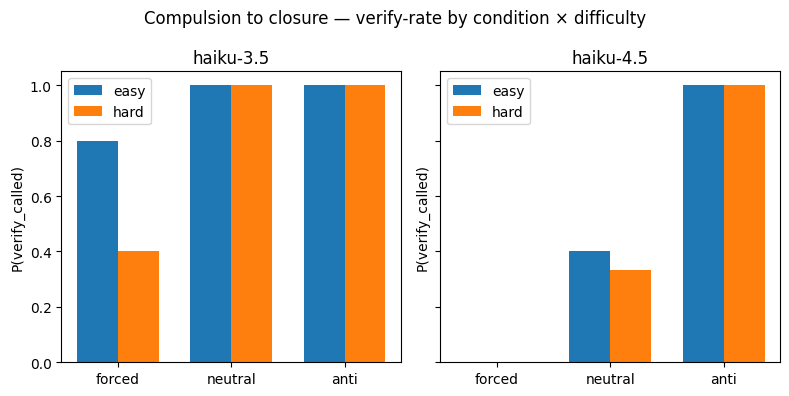

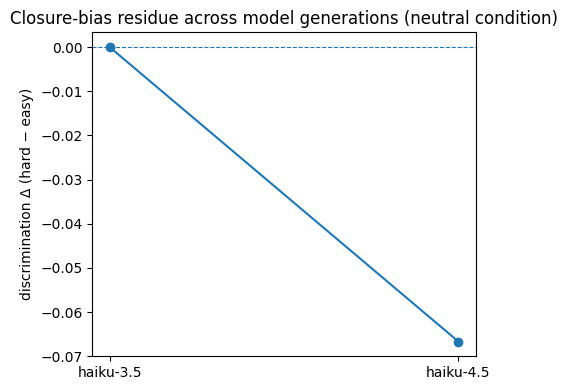

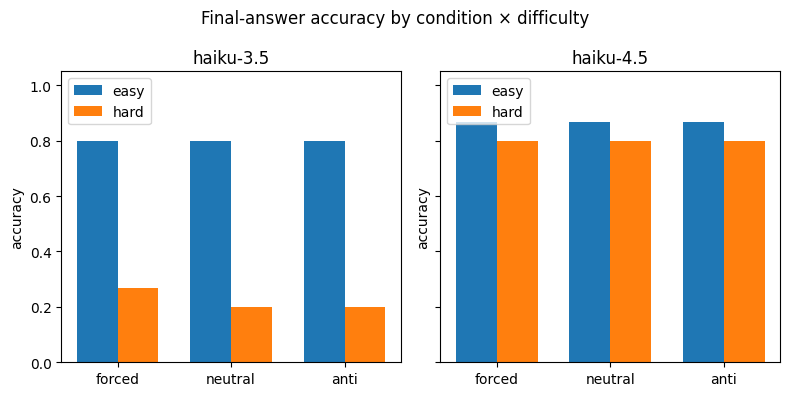

In [ ]:
plot_headline(summary)
plot_generation_effect(discr)
plot_accuracy(summary)

## 9. Sanity checks and caveats

Run these after the sweep to validate that the experiment's preconditions held.

- The agent really had only our tools (init message audit).
- The model called `submit` on a high fraction of trials (else `max_turns` is too tight).
- The `forced` condition had zero `verify` calls (since the tool wasn't even exposed).
- `verify` was not used as an oracle (no trial submits exactly the candidate that verify just rejected, repeatedly).

In [ ]:
df = df_all

# (a) tool isolation — every trial's init_tools should look like only mcp__probe__... (+ system).
leak = df[df["init_tools"].str.contains(r"\b(?:Bash|Read|Edit|Write|Glob|Grep|WebFetch)\b", regex=True, na=False)]
print("trials with leaked builtins in init_tools:", len(leak))

# (b) submit completion rate.
sub_rate = df.groupby("condition")["submit_calls"].apply(lambda s: (s > 0).mean())
print("\nsubmit completion rate by condition:")
print(sub_rate.to_string())

# (c) forced condition exposed no verify tool — must be 0 calls.
forced_verify = df.query("condition == 'forced'")["verify_calls"].sum()
print(f"\nverify calls in forced condition (must be 0): {forced_verify}")

# (d) total cost.
print(f"\ntotal sweep cost: ${df['cost_usd'].sum():.2f}")

trials with leaked builtins in init_tools: 0

submit completion rate by condition:
condition
anti       0.966667
forced     0.966667
neutral    1.000000

verify calls in forced condition (must be 0): 20

total sweep cost: $2.64


### Caveats and known limitations

- **Tool-design contingency.** Results are specific to this `verify`/`submit` framing. A different tool framing might reveal a smaller or larger bias. The bias is properly *operationalized*, not *defined*, by this probe.
- **Pool size.** N=3 trials × 60 problems gives noisy CIs. Scale to N=10 once headline shape is confirmed.
- **Single tool dimension.** This probe measures the *terminate-vs-recheck* dimension only. The *solve-vs-decompose* dimension needs the composed-MATH probe (notebook 03 to come).
- **Tool-use-reliability confound on old models.** If Claude 3 Haiku fails to emit valid tool calls reliably, low verify-rate could be capability rather than bias. Inspect its `init_tools`/`stop_reason` distributions before drawing conclusions for that tier.
- **Verify-as-oracle leakage.** The tool returns OK/Discrepancy. A model could in principle exploit this by submitting candidates and reading the tool's reply as ground-truth signal. Behavioral mitigation: framed as self-check, not oracle. Empirical mitigation: inspect trajectories for repeat-verify-then-submit-different-answer patterns.

### Next probes (later notebooks)

- **03 — composed-MATH depth probe** for the *solve-vs-decompose* dimension.
- **04 — disguised-decomposition probe** where the composition is hidden behind a unified word problem (pushes the bias harder).